# 03 · Feature Engineering

En este proyecto no se entrena ningún modelo: un LLM recibe el tuit y devuelve una etiqueta. Aun así hay trabajo de ingeniería de características, y este notebook lo documenta.

**Qué significa aquí "feature engineering"**

1. **Qué ve el LLM**: cómo se normaliza el tuit antes de ponerlo en el prompt, y qué información no se le da (la variedad).
2. **Catálogo de 24 características** lingüísticas y de superficie, calculadas con reglas. Sirven para entender el corpus, para contrastar lo que reporte el agente de Percepción y para armar líneas base.
3. **Representaciones TF-IDF** (palabras y caracteres), usadas **solo como piso de comparación**.
4. **Control de atajos**: qué características delatan el país en lugar del sentimiento.

**Higiene.** Todo lo que se ajusta (vectorizadores, escalado, modelos de referencia) se ajusta solo con *train* y se mide solo en *dev*. No se toca ninguna partición de prueba. Los modelos de regresión logística de este notebook son referencias, no el experimento.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ / "scripts" / "features"))
sys.path.insert(0, str(RAIZ / "scripts" / "eda"))
import feature_utils as F
import eda_utils as E
import run_features as RF

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)
FIG = RAIZ / "docs" / "features" / "figuras"

corpus = E.cargar_corpus(RAIZ / "data")
M = F.construir_matriz(corpus)
print(f"{len(corpus):,} tuits · {M.shape[1]} características")

7,267 tuits · 24 características


## 1. Qué ve el LLM

Antes de armar cualquier característica, hay que decidir qué texto entra al prompt. La función `normalizar_para_llm` hace lo mínimo y deja intactas las señales que el modelo debe ver.

In [2]:
ejemplos = [
    "@juan  mira esto https://t.co/xx  JAJAJA qué bueeeno!!! 😂",
    "No me gusta nada...   @maria no vuelvo más",
    "Qué lindo día, gatitos por todos lados :)",
]
pd.DataFrame({"original (inventado)": ejemplos, "lo que ve el LLM": [F.normalizar_para_llm(t) for t in ejemplos]})

,original (inventado),lo que ve el LLM
0,@juan mira esto https://t.co/xx JAJAJA qué bueeeno!!! 😂,@USUARIO mira esto URL JAJAJA qué bueeeno!!! 😂
1,No me gusta nada... @maria no vuelvo más,No me gusta nada... @USUARIO no vuelvo más
2,"Qué lindo día, gatitos por todos lados :)","Qué lindo día, gatitos por todos lados :)"


**Decisiones.**
- Las **@menciones** pasan a `@USUARIO` y los **enlaces** a `URL`: privacidad y menos ruido, pero se conserva el hecho de que el tuit es una respuesta.
- **No se toca** mayúsculas, puntuación, alargamientos, emojis ni tildes: son señales de tono que el LLM debe ver.
- **No se le da la variedad.** El sistema no debe saber de qué país es el tuit. La variedad solo se usa para reportar resultados por país.

## 2. Catálogo de características

Cada característica tiene un grupo, una definición y una razón para incluirla. Todas son reglas simples y transparentes.

In [3]:
cat = F.catalogo_features()
display(cat.groupby("grupo").size().rename("n").to_frame().T)
cat[["feature", "grupo", "tipo", "definicion"]]

grupo,conversacional,estructural,expresividad,fenomeno,lexico
n,4,6,7,4,3


,feature,grupo,tipo,definicion
0,n_caracteres,estructural,conteo,Longitud del tuit en caracteres.
1,n_palabras,estructural,conteo,Número de palabras (secuencias de letras).
2,long_media_palabra,estructural,razón,Caracteres de letras por palabra.
3,n_oraciones,estructural,conteo,Segmentos terminados en . ! ? (mínimo 1).
4,ratio_mayusculas,estructural,razón,Fracción de letras en mayúscula.
5,n_digitos,estructural,conteo,Cantidad de dígitos.
6,n_exclamaciones,expresividad,conteo,Signos ! en el tuit.
7,n_interrogaciones,expresividad,conteo,Signos ? en el tuit.
8,n_puntos_suspensivos,expresividad,conteo,Secuencias de 3 o más puntos.
9,n_alargamientos,expresividad,conteo,Letras repetidas 3 o más veces (holaaa).


**Lectura.** Son 24 características en cinco grupos: *estructural* (6), *expresividad* (7), *conversacional* (4), *fenómeno* (4, las reglas del agente de Percepción) y *léxico* (3). Las de fenómeno son las mismas heurísticas del script de auditoría, con una corrección de nombre: lo que antes se llamaba "sarcasmo" aquí es `n_risas`, porque solo detecta risas. El **léxico** (`n_lex_positivo`, `n_lex_negativo`) es una lista corta y propia, sin validar: se incluye para medir cuánta señal da una lista pequeña, no como léxico de referencia.

## 3. Cómo se distribuyen

In [4]:
est = M.describe().T[["mean", "50%", "max"]].round(2)
est["% tuits con al menos 1"] = ((M > 0).mean() * 100).round(1)
est

,mean,50%,max,% tuits con al menos 1
n_caracteres,89.90,92.00,146.00,100.0
n_palabras,16.06,16.00,35.00,100.0
long_media_palabra,4.58,4.42,14.14,100.0
n_oraciones,1.57,1.00,9.00,100.0
ratio_mayusculas,0.05,0.03,0.84,88.6
n_digitos,0.58,0.00,24.00,21.5
n_exclamaciones,0.31,0.00,18.00,14.9
n_interrogaciones,0.11,0.00,8.00,7.7
n_puntos_suspensivos,0.11,0.00,5.00,9.2
n_alargamientos,0.06,0.00,5.00,4.9


**Lectura.** Casi todas las características son conteos pequeños y muy dispersos. `n_emojis` (0,2% de los tuits), `n_emoticonos` (0,1%), `tiene_url` (0,6%) y `n_marcadores_ingles` (0,9%) casi no aparecen, así que no pueden aportar mucho al sentimiento ni al análisis por país. Lo que sí está presente de forma amplia es la longitud (100% de los tuits), las mayúsculas (89%), las menciones (49%) y la negación (34%).

## 4. ¿Qué características distinguen las etiquetas?

Se mide cuánto cambia cada característica entre NEG, NEU y POS con una prueba de Kruskal-Wallis. Se reporta el tamaño de efecto (epsilon cuadrado, de 0 a 1), porque con 7.267 tuits casi todo sale "significativo".

In [5]:
aso = F.asociacion_univariada(M, corpus["etiqueta"], corpus["variedad"])
aso[["feature", "grupo", "efecto_etiqueta", "efecto_variedad", "mas_ligada_a"]].head(12)

,feature,grupo,efecto_etiqueta,efecto_variedad,mas_ligada_a
0,n_lex_positivo,lexico,0.13856,0.00646,etiqueta
1,n_lex_negativo,lexico,0.06411,0.00419,etiqueta
2,n_negaciones,fenomeno,0.04686,0.00172,etiqueta
3,n_exclamaciones,expresividad,0.04632,0.01166,etiqueta
4,n_menciones,conversacional,0.02702,0.04117,variedad
5,long_media_palabra,estructural,0.02696,0.00786,etiqueta
6,empieza_con_mencion,conversacional,0.02006,0.03488,variedad
7,ratio_mayusculas,estructural,0.01423,0.00333,etiqueta
8,n_intensificadores,lexico,0.01265,0.00424,etiqueta
9,n_oraciones,estructural,0.01192,0.00131,etiqueta


In [6]:
F.medias_por_etiqueta(M, corpus["etiqueta"]).loc[["n_lex_positivo", "n_lex_negativo", "n_negaciones", "n_exclamaciones", "n_interrogaciones", "n_menciones", "long_media_palabra"]]

etiqueta,NEG,NEU,POS
n_lex_positivo,0.161,0.253,0.677
n_lex_negativo,0.222,0.063,0.033
n_negaciones,0.618,0.445,0.254
n_exclamaciones,0.172,0.229,0.583
n_interrogaciones,0.111,0.136,0.066
n_menciones,0.503,0.711,0.759
long_media_palabra,4.410,4.608,4.765


**Lectura.**
- La señal más fuerte la da el **léxico mínimo**: `n_lex_positivo` (epsilon² = 0,139) y `n_lex_negativo` (0,064). Una lista de unas 30 palabras por lado (28 positivas y 29 negativas) ya separa bastante las clases.
- Le siguen la **negación** (0,047) y las **exclamaciones** (0,046). Los tuits POS tienen en promedio 0,58 exclamaciones frente a 0,17 en los NEG. Los NEG tienen más negaciones (0,62 frente a 0,25 en los POS).
- Las preguntas son más frecuentes en NEU que en POS, y el resto de las características de expresividad (emojis, emoticonos, mayúsculas) casi no distingue nada.
- La **longitud en caracteres no distingue** las etiquetas (epsilon² ≈ 0).

### Las banderas del agente de Percepción, una por una

Las cuatro reglas que imitan al agente de Percepción, ¿dicen algo del sentimiento por sí solas?

In [7]:
F.perfil_pistas(corpus, M)

,bandera,n,NEG_pct,NEU_pct,POS_pct
0,(todos los tuits),7267,39.1,32.0,28.9
1,diminutivo_afectivo,941,34.1,29.4,36.5
2,doble_negacion,671,55.1,30.3,14.6
3,code_switching,64,39.1,31.2,29.7
4,marcador_risa,458,29.9,36.9,33.2


**Lectura.** La **doble negación** es la bandera más informativa: entre los tuits que la activan, 55,1% son NEG frente a 39,1% en el total. El **diminutivo** inclina hacia POS (36,5% frente a 28,9%) y la **risa** aleja de NEG (29,9% frente a 39,1%), pero con efectos moderados. El **code-switching** (64 tuits) se comporta como el total y no aporta nada. Esto es importante para la hipótesis del proyecto: las banderas como reglas aisladas dicen poco, así que el valor del agente de Percepción tendría que estar en **interpretarlas en contexto**, por ejemplo distinguir una risa irónica de una alegre, algo que una regla no puede hacer.

## 5. Redundancia

In [8]:
F.correlaciones_altas(M)

,feature_a,feature_b,spearman_abs
0,n_caracteres,n_palabras,0.937
1,n_menciones,empieza_con_mencion,0.878


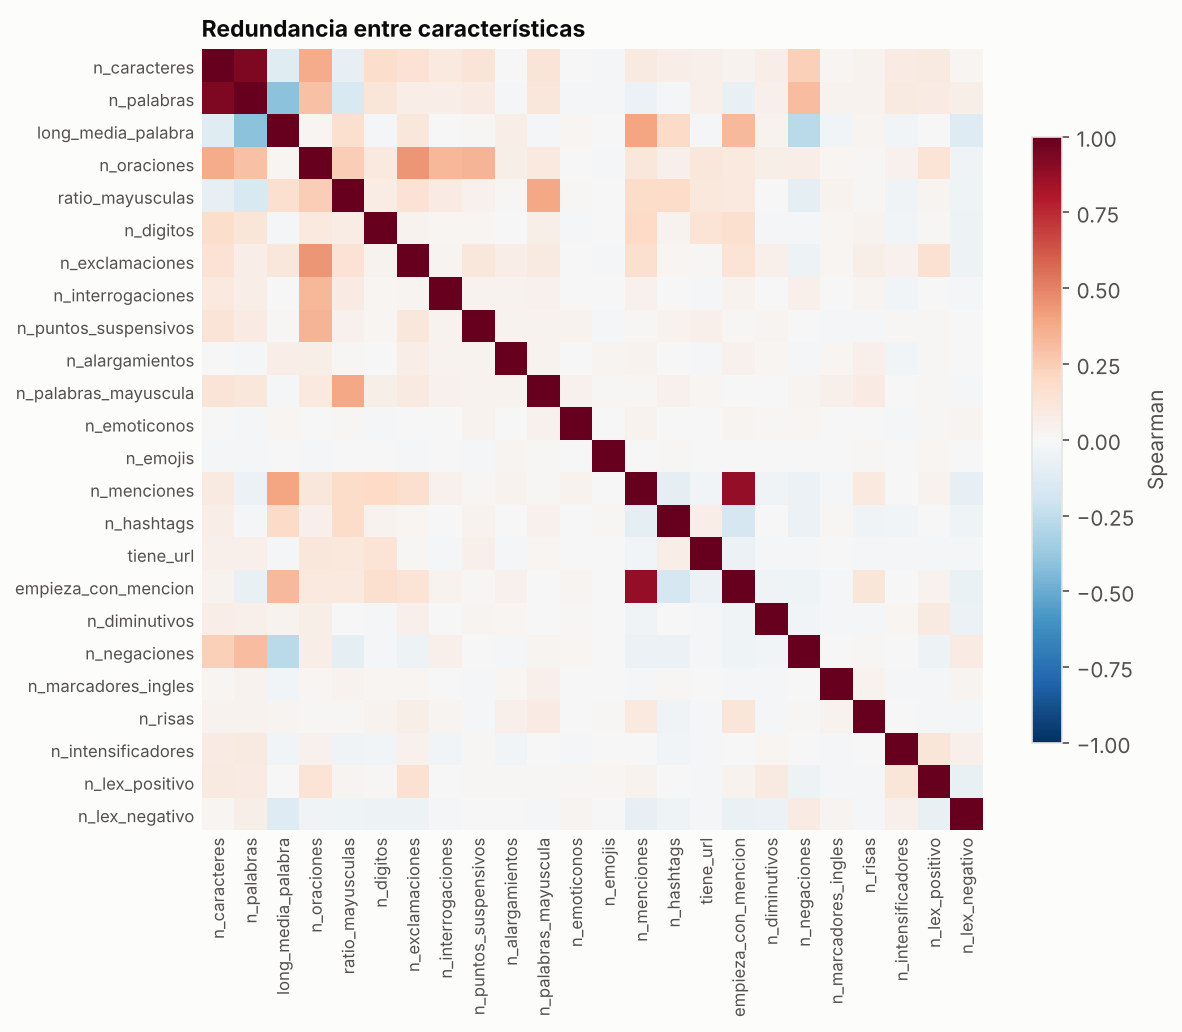

In [9]:
display(Image(filename=str(FIG / "fig04_correlaciones.png"))) if (FIG / "fig04_correlaciones.png").exists() else RF.fig_correlaciones(M, FIG / "fig04_correlaciones.png")

**Lectura.** Hay dos pares redundantes: `n_caracteres` con `n_palabras` (Spearman 0,94) y `n_menciones` con `empieza_con_mencion` (0,88). **Decisión:** para cualquier modelo de referencia con características numéricas conviene conservar una sola de cada par. Para el catálogo se dejan las dos porque cada una se explica por sí sola.

## 6. ¿Delatan el país en lugar del sentimiento?

Si una característica se relaciona más con la variedad que con la etiqueta, un sistema podría usarla como atajo. Aquí cada punto es una característica: arriba a la izquierda están las que hablan de sentimiento y abajo a la derecha las que hablan de país.

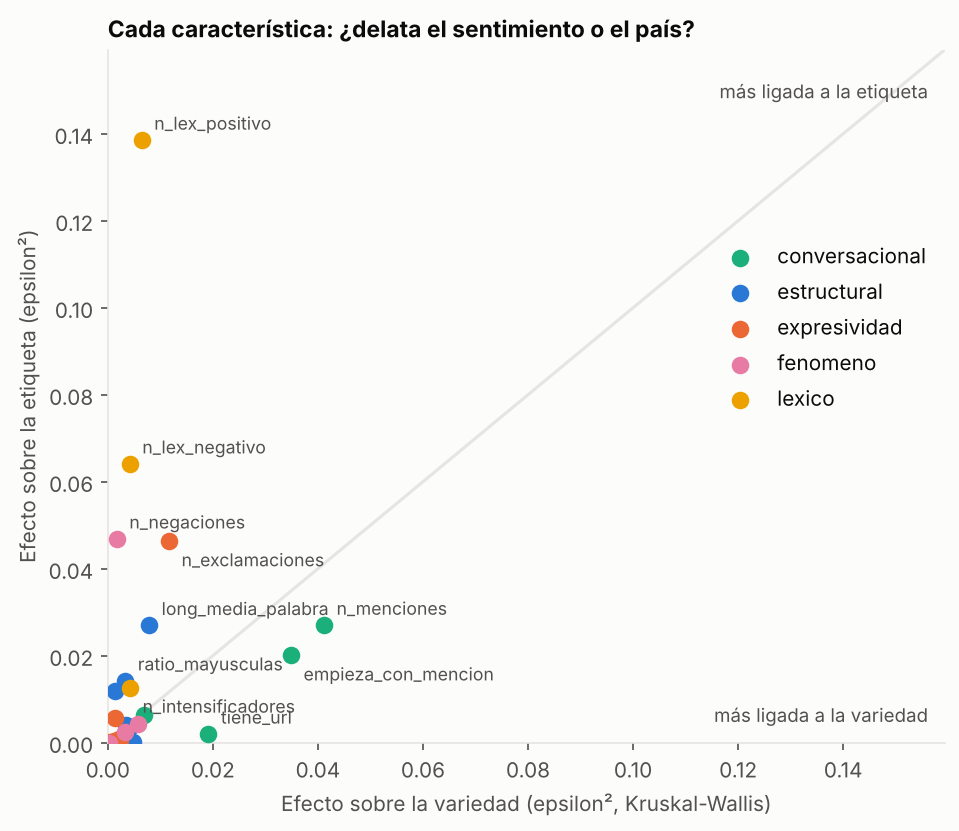

In [10]:
display(Image(filename=str(FIG / "fig02_efecto_etiqueta_vs_variedad.png")))

In [11]:
aso[aso.mas_ligada_a == "variedad"][["feature", "grupo", "efecto_etiqueta", "efecto_variedad"]].head(8)

,feature,grupo,efecto_etiqueta,efecto_variedad
4,n_menciones,conversacional,0.02702,0.04117
6,empieza_con_mencion,conversacional,0.02006,0.03488
10,n_hashtags,conversacional,0.00645,0.00692
12,n_diminutivos,fenomeno,0.00421,0.00568
14,n_palabras,estructural,0.00370,0.00427
15,n_risas,fenomeno,0.00241,0.00323
16,tiene_url,conversacional,0.00199,0.01915
17,n_puntos_suspensivos,expresividad,0.00082,0.00206


In [12]:
F.prediccion_de_variedad(corpus)

,representacion,n_dev,n_variedades,azar_aprox,accuracy_dev,macro_f1_dev,macro_f1_ic_inf,macro_f1_ic_sup
0,TF-IDF de palabras,2465,5,0.2,0.3858,0.3772,0.3609,0.3939
1,TF-IDF de caracteres,2465,5,0.2,0.3862,0.3758,0.3583,0.3930


**Lectura.**
- Las características **más ligadas al país que al sentimiento** son sobre todo las conversacionales: `n_menciones`, `empieza_con_mencion`, `tiene_url` y `n_hashtags`. Reflejan cómo se recolectó el corpus y el estilo de cada comunidad, no la polaridad.
- Solo con el texto, un clasificador de palabras adivina el país con un Macro-F1 de 0,38, frente a 0,20 al azar. Es decir, el texto **delata parcialmente el país** aunque no se lo digamos al LLM. Por eso la regla de no pasarle la variedad no es una garantía total de que no la use.
- **Decisión:** cualquier característica conversacional que se use en un modelo de referencia debe revisarse por país, y los resultados por país se reportan con el contexto temporal que ya vimos en el EDA.

## 7. Comparar representaciones (pisos de referencia)

Se compara qué representación del texto aporta más señal con regresión logística entrenada con *train* y medida en *dev*. **No es el experimento**: sirve para saber qué piso tiene que superar un sistema con LLM y si las características a mano aportan algo más allá de las palabras.

In [13]:
resumen, por_var = F.comparar_representaciones(corpus)
resumen

,representacion,n_dev,accuracy_dev,macro_f1_dev,macro_f1_ic_inf,macro_f1_ic_sup
0,0. Siempre la clase mayoritaria,2465,0.3895,0.1869,0.1801,0.1932
1,"1. Superficie (estructural, expresividad, conversacional)",2465,0.4381,0.4268,0.4072,0.4468
2,2. Superficie + fenómenos + léxico mínimo,2465,0.5120,0.5085,0.4883,0.5284
3,3. TF-IDF de palabras,2465,0.5615,0.5556,0.5363,0.5749
4,4. TF-IDF de caracteres,2465,0.5712,0.5678,0.5472,0.5880
5,5. TF-IDF palabras + caracteres,2465,0.5712,0.5660,0.5457,0.5852
6,6. TF-IDF palabras + todas las numéricas,2465,0.5611,0.5576,0.5375,0.5754


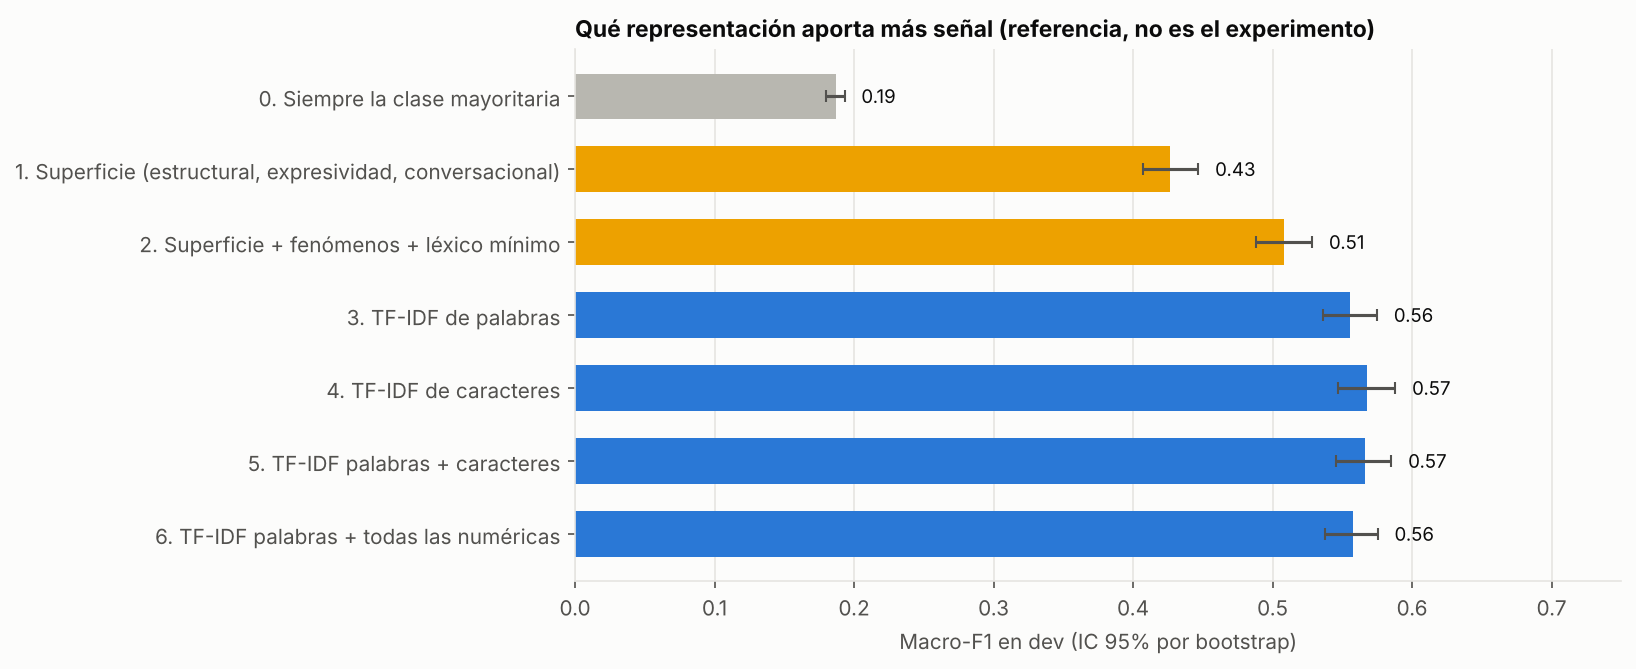

In [14]:
display(Image(filename=str(FIG / "fig01_comparacion_representaciones.png")))

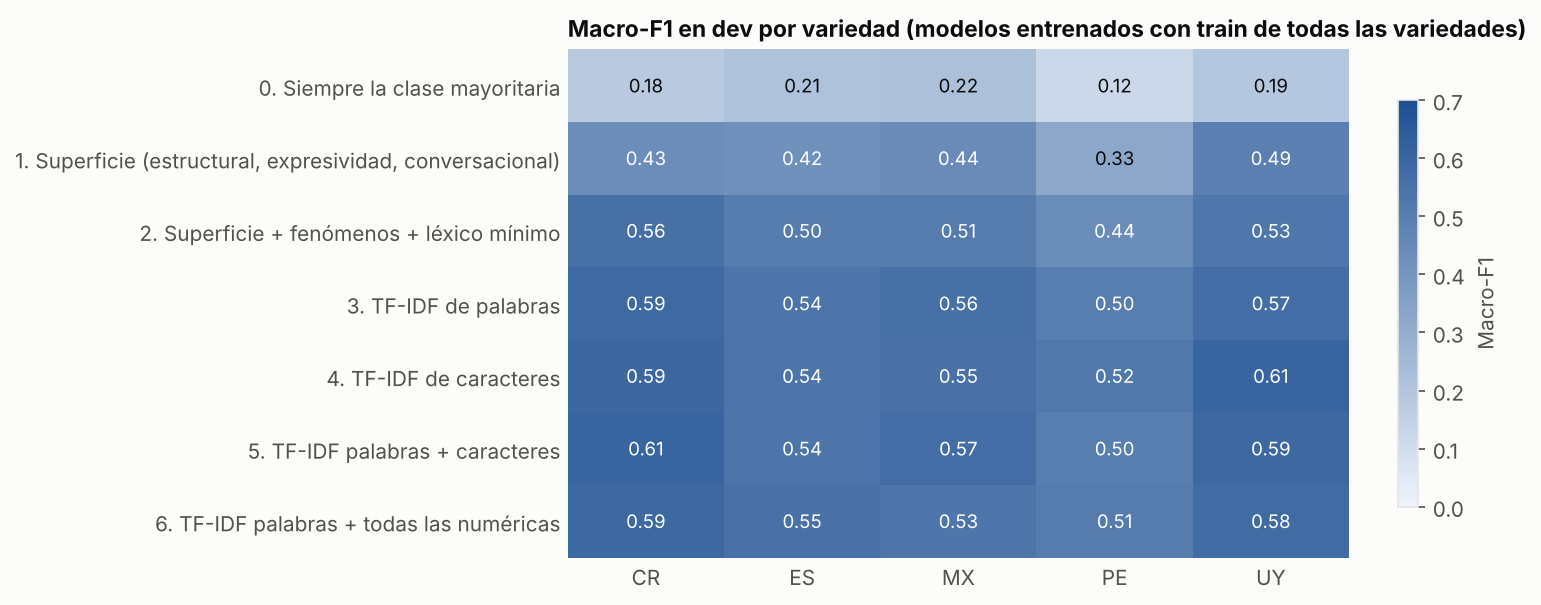

In [15]:
display(Image(filename=str(FIG / "fig03_macro_f1_por_variedad.png")))

**Lectura.**
- Siempre la clase mayoritaria: Macro-F1 de 0,19. Las características de **superficie solas** (longitud, puntuación, menciones) llegan a 0,43, así que una parte de la señal está en la forma del texto.
- Agregar **fenómenos y léxico mínimo** sube a 0,51: una lista corta de palabras vale mucho.
- **TF-IDF de palabras (0,56) y de caracteres (0,57)** son el mejor piso. Combinarlos entre sí o con las características numéricas **no mejora** (0,56 a 0,57, con intervalos que se solapan), así que las características hechas a mano no suman sobre las palabras.
- Por país, **Perú** queda más abajo en casi todos los modelos (0,44 a 0,52), en línea con lo visto en el EDA sobre su proporción de neutrales.
- Conclusión práctica: un sistema con LLM debería compararse al menos contra el piso de **0,56 a 0,57**. Si un monoagente queda por debajo de TF-IDF, hay que reportarlo.

## 8. Palabras con más peso por clase

In [16]:
F.terminos_por_clase(corpus).pivot(index="rank", columns="clase", values="termino")

clase,NEG,NEU,POS
rank,,,
1,triste,yo,feliz
2,no,si,gracias
3,me,hola,amo
4,feo,usuario,buena
5,peor,creo,bonito
6,odio,igual,lindo
7,extraño,por,hermoso
8,mala,normal,buen
9,ni,quiera,mejor


**Lectura.** Las palabras de NEG (*triste, feo, peor, odio*) y POS (*feliz, gracias, amo, bonito*) son afectivas y esperables. En **NEU** aparecen palabras conversacionales y de hedging (*yo, si, hola, creo, igual, normal*) y `usuario`, que viene de las menciones normalizadas: los tuits que empiezan respondiendo a alguien tienden a ser neutros. Eso confirma que parte de la señal de NEU es de estilo conversacional, y no de contenido, y que esa señal está ligada al país (sección 6).

## 9. Conclusiones y decisiones

1. **Texto del prompt:** normalización mínima (`@USUARIO`, `URL`), sin tocar mayúsculas, puntuación, emojis ni alargamientos, y sin pasar la variedad.
2. **Catálogo:** 24 características en 5 grupos, todas con definición y justificación (`docs/features/tablas/catalogo_features.csv`).
3. **Señal real:** el léxico, la negación y las exclamaciones son lo que más distingue las etiquetas. La longitud, los emojis y el code-switching casi no aportan.
4. **Agente de Percepción:** como reglas aisladas, sus banderas dicen poco (salvo la doble negación). Su valor tiene que estar en interpretar en contexto, y eso es lo que el experimento debe medir.
5. **Redundancia:** quitar una característica de cada par redundante en modelos numéricos.
6. **Atajos:** las características conversacionales se relacionan más con el país que con el sentimiento. Usarlas con cuidado y reportar por país con contexto temporal.
7. **Pisos de referencia:** clase mayoritaria (0,19) y TF-IDF (0,56 a 0,57). Comparar el LLM contra ambos.
8. **Pendientes:** validar a mano las reglas (muestra de `docs/eda/tablas/muestra_validar_heuristicas.csv`) y, si se quiere un léxico de referencia, sustituir el léxico mínimo por uno validado.